# Flicker-bounded moves: can the frames of a move keep every moving trap bright?

**Question:** Can the intermediate holograms of a move be computed so that every moving trap stays bright, and does the answer hold for the long moves of a real sort?

- Level: 4, beyond the state of the art (claim BS-2).
- Prerequisites: `07-feedback-and-dynamics/04-moving-atoms-by-linear-phase-interpolation`, which builds the sequence of linear phase interpolation that this notebook compares with.
- Reading time: about 30 minutes. The notebook runs in about two minutes.

## Objectives

The previous notebook ended with a number that LPI cannot change by itself: between two of its frames a moving trap can dim to under half its mean, because LPI interpolates two end holograms and never optimises what lies between them. An atom held in that trap during the dim instant may be lost. B2 asks a different question of the same move: if every frame is optimised while the phases of the traps follow a smooth path from start to end, can the dimmest instant of every moving trap be kept at 0.9 of its mean, and what does the path of the phases have to be for that? By the end you can:

- say what is locked in B2 and what is free, and how the positions and the phases move;
- score two different sequences with the same transient model;
- measure on the acceptance task of B2 how far each sequence dips, over three seeds;
- test the claim on a harder problem, the long moves of the sort of case C10, at the default number of frames and at the number the move needs, and say what then fails;
- say what the transient model assumes.

## Setup


The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` on Windows). This notebook uses two packages, at these exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot publishes no package of its own: its methods live in the pipeline folder `data-pipeline/`, and the next cell puts
that folder on the import path and imports the functions the notebook calls.

In [1]:
# the tools, their versions, and the pipeline folder on the import path
import sys
from dataclasses import replace
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.cases.library import random_loading
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.geometry import focal_bin_m
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.traps import TrapSet, square_grid
from pipeline.model.holo.core.types import Budget, Target
from pipeline.model.holo.methods.baseline import m07_phase_fixed_wgs
from pipeline.model.holo.methods.beyond import b2_flicker_bounded
from pipeline.model.holo.methods.beyond.b2_flicker_bounded import transient_min_ratio, trajectory
from pipeline.model.holo.methods.control import m16_rearrangement

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Data

The notebook takes the optical setup of case C10 of `data/examples/cases.json` (256 x 256 pixels, a focal bin of about 0.5 micrometres) and builds the acceptance task of B2 on it. The last step uses the sort of C10 itself, with its loading and target block.

- Owner: this repository; the case and the task are synthetic.
- Licence class: generated data under the repository's own licence, no third-party dataset.
- File: `data/examples/cases.json`, case C10.

In [2]:
# case C10 supplies the optical setup and, for the last step, the sort of 36 targets from 52 atoms
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C10"]
setup = build.setup_of(rec)
bin_m = focal_bin_m(setup)
print(rec["case_id"], "| focal bin", round(bin_m * 1e6, 3), "um | SLM", setup.n_pix, "x", setup.n_pix, "pixels")

C10_rearrangement | focal bin 0.498 um | SLM 256 x 256 pixels


## Method

### Phase-continuous frames

B2 computes $S + 1$ frames. The positions of the traps follow the minimal-jerk profile $x_m(s) = x_m(0) + (x_m(S) - x_m(0))\,(10\tau^3 - 15\tau^4 + 6\tau^5)$ with $\tau = s/S$, which starts and stops with zero velocity and acceleration. The optical phases of the traps follow the same profile, $\theta_m(s) = \theta_m(0) + \mathrm{wrap}(\theta_m^\text{end} - \theta_m(0))\,h(\tau)$, and by default they are held, $\theta^\text{end} = \theta(0)$. Each frame is a phase-fixed weighted GS (Kim et al., 2019) in which the target amplitudes are $w_m a_m e^{i\theta_m(s)}$: the weights $w_m$ adapt so that the traps are equal, but the phases are those of the trajectory, not free. The frame starts from the previous frame's hologram and weights, and runs 10 iterations. The method refuses a sequence in which the phase moves more than 0.3 rad per frame.

The transient intensity is a model, not a measurement. Between frames $s$ and $s+1$ the displayed field is taken as the blend $(1 - a)\,e^{i\phi_s} + a\,e^{i\phi_{s+1}}$, with $a$ from 0 to 1, as the liquid crystal relaxes, and each trap is read at its position $x_m(s + a)$. The score of a trap is its lowest intensity over $s$ and $a$ divided by its mean over the frames. The model is the pipeline's reading of the LPI paper and is marked unverified in the method; it is the same function for every sequence below, so a comparison with it is fair even if its absolute values are not. The first cell builds the acceptance task of B2: a 4 x 4 lattice with a spacing of 8 focal bins whose two right columns move 4 bins in x.

In [3]:
# the acceptance task of B2: a 4 x 4 lattice at 8 focal bins, the two right columns move 4 bins in x
start = square_grid(4, 4, 8 * bin_m * 1e6)
dest = TrapSet(replace(t, x_m=t.x_m + (4 * bin_m if i % 4 >= 2 else 0.0)) for i, t in enumerate(start))
moving = np.array([d.x_m != s.x_m for s, d in zip(start, dest)])
print(f"{len(start)} traps, {int(moving.sum())} of them move {4} bins in x")
print("x of the first row, from and to (bins):",
      np.round(start.x_m[:4] / bin_m, 1), np.round(dest.x_m[:4] / bin_m, 1))

16 traps, 8 of them move 4 bins in x
x of the first row, from and to (bins): [-12.  -4.   4.  12.] [-12.  -4.   8.  16.]


## State of the art

The state of the art is LPI (the arXiv 2501.01391 recipe, implemented in M16): two phase-fixed WGS holograms, one for the start and one for the end, the position, amplitude and phase of every trap read from them and interpolated linearly, and the inverse transform at every step. The cell runs it with 12 steps (13 frames, the size of the sort that the paper does) for three seeds, and scores the frames with the transient model of B2, with the positions that LPI uses, which are linear in the step.

In [4]:
# LPI of M16 over 12 steps, three seeds; every sequence is scored by the transient model of B2, with linear
# positions
lpi = {}
n_frames = {}
for seed in (1, 2, 3):
    run = m16_rearrangement.run(setup, Target.from_traps(dest), budget=Budget(30), rng=Rng(seed), atoms=start,
                                alpha=1.5, max_step_bins=4 / 12)
    order = run.meta["assignment"]
    origin = TrapSet(replace(t, x_m=start.x_m[order[i]], y_m=start.y_m[order[i]]) for i, t in enumerate(dest))
    along = trajectory(origin, dest, len(run.meta["frames"]), profile=lambda tau: tau)
    n_frames[seed] = len(run.meta["frames"])
    lpi[seed] = transient_min_ratio(setup, list(run.meta["frames"]), along)[moving]
for seed, ratio in lpi.items():
    print(f"seed {seed}: {n_frames[seed]} frames | "
          f"lowest transient intensity of a moving trap "
          f"{ratio.min():.3f} | median {np.median(ratio):.3f}")

seed 1: 13 frames | lowest transient intensity of a moving trap 0.669 | median 0.846
seed 2: 13 frames | lowest transient intensity of a moving trap 0.700 | median 0.753
seed 3: 13 frames | lowest transient intensity of a moving trap 0.642 | median 0.807


LPI keeps the median moving trap at 0.846, 0.753 and 0.807 of its mean, but the worst trap of each seed dips to 0.669, 0.700 and 0.642. Two of the three are below the 0.7 that the paper reports for its moving traps and the third is on it, and none is near 0.9. The dips differ by seed because the two end holograms are independent: each has its own free trap phases, and the interpolation between two unrelated sets of phases passes through whatever interference they make. The table does not say how an atom would fare in a dip of 0.64, since that depends on the trap depth, which the notebook does not model. B2 sets a target on the dip itself: its method ladder asks for a minimum of at least 0.9.

## Beyond the state of the art

### B2 on its acceptance task (BS-2)

The gap that B2 addresses is that LPI does not optimise the frames it creates, so the intermediate holograms are as uneven as the interpolation makes them. The claim is that locking the trap phases to a smooth trajectory and re-optimising each frame keeps the lowest transient intensity of a moving trap at or above 0.9 of its mean. The cell runs B2 on the same task, the same three seeds and 13 frames, and prints the lowest intensity, the median, and the worst relative standard deviation of any single frame (a check that the optimisation of each frame has not given up its uniformity).

In [5]:
# B2 on the same task: 13 frames, trap phases locked to a smooth trajectory, each frame a phase-fixed WGS
# from the last
b2_runs = {}
for seed in (1, 2, 3):
    b2_runs[seed] = b2_flicker_bounded.run(setup, Target.from_traps(start), budget=Budget(30), rng=Rng(seed),
                                           destination=dest)
for seed, res in b2_runs.items():
    ratio = res.meta["transient_ratio"][moving]
    worst_frame = max(h["rel_std"] for h in res.history)
    print(f"seed {seed}: {res.meta['n_frames']} frames | lowest transient intensity "
          f"{ratio.min():.3f} | median {np.median(ratio):.3f} | worst spread of a frame {worst_frame:.2f} %")

seed 1: 13 frames | lowest transient intensity 0.916 | median 0.925 | worst spread of a frame 0.36 %
seed 2: 13 frames | lowest transient intensity 0.920 | median 0.932 | worst spread of a frame 0.14 %
seed 3: 13 frames | lowest transient intensity 0.926 | median 0.934 | worst spread of a frame 0.39 %


The figure plots, sorted, the lowest transient intensity of each of the 24 moving traps (3 seeds times 8) for LPI and for B2, with the lines at 0.7 and 0.9.

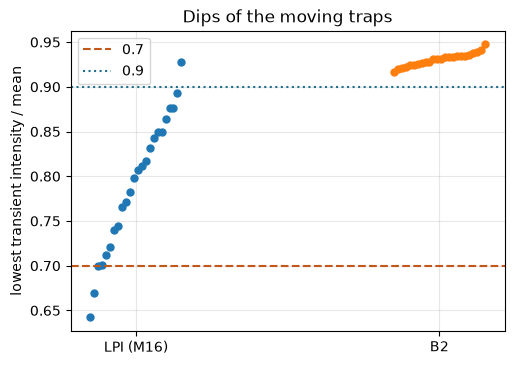

In [6]:
# lowest transient intensity of every moving trap (3 seeds x 8 traps), LPI against B2
pooled = {"LPI (M16)": np.concatenate(list(lpi.values())),
          "B2": np.concatenate([res.meta["transient_ratio"][moving] for res in b2_runs.values()])}
fig, ax = plt.subplots(figsize=(5.6, 3.9))
for k, (name, values) in enumerate(pooled.items()):
    ax.plot(np.full(values.size, k) + np.linspace(-0.15, 0.15, values.size), np.sort(values), "o", markersize=5)
ax.axhline(0.7, color="#c2571a", linestyle="--", label="0.7")
ax.axhline(0.9, color="#1f6f8b", linestyle=":", label="0.9")
ax.set_xticks([0, 1])
ax.set_xticklabels(list(pooled))
ax.set_ylabel("lowest transient intensity / mean")
ax.set_title("Dips of the moving traps")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

B2 reaches 0.916, 0.920 and 0.926 for the lowest moving trap in the three seeds, with medians of 0.925 to 0.934: the whole B2 column sits above the 0.9 line, in a tight band up to about 0.95, where the LPI points range from 0.64 to 0.93, two lie under 0.7 and only one reaches 0.9. The single frames stay uniform, with a worst relative standard deviation of 0.14 to 0.39 percent, so the gain is not paid in the quality of the holograms. The acceptance criterion holds on all three seeds, and B2 is above LPI on each. The figure is for one task, in which the traps move by half a lattice spacing, and for the transient model of the pipeline; it does not say that the same margin holds for a longer move, which the next step tests.

### A longer problem: the sort of case C10

The acceptance task moves each trap by 4 bins. The sort of C10 moves atoms by up to 29 bins, many traps at once, in a field where the others are held. The cell lets M16 plan the sort with the Hungarian assignment at the exponent 1.0 (the plan with no crossing paths in the previous notebook) and builds LPI's frames, then takes M16's own assignment as the one plan of every arm below: each trap's start and end positions, and the traps that move. It prints how many traps move and the longest move.

In [7]:
# the sort of case C10 (52 atoms to 36 targets, alpha = 1.0) as M16 plans it: one plan for every arm below
sites = {t["id"]: t for t in rec["target"]["traps"]}
loaded, wanted = random_loading(rec), rec["rearrangement"]["target_ids"]
atoms = build.trapset_of([sites[i] for i in loaded])
goal = build.trapset_of([sites[i] for i in wanted])
lpi10 = m16_rearrangement.run(setup, Target.from_traps(goal), budget=Budget(30), rng=Rng(1), atoms=atoms,
                              alpha=1.0, max_step_bins=1.25)
pick = lpi10.meta["assignment"]
origin10 = TrapSet(replace(t, x_m=atoms.x_m[pick[i]], y_m=atoms.y_m[pick[i]]) for i, t in enumerate(goal))
moving10 = np.array([np.hypot(a.x_m - g.x_m, a.y_m - g.y_m) > 0 for a, g in zip(origin10, goal)])
longest = max(np.hypot(a.x_m - g.x_m, a.y_m - g.y_m) for a, g in zip(origin10, goal)) / bin_m
print(f"{len(goal)} traps, {int(moving10.sum())} moving, longest move {longest:.1f} bins")
print(f"the same moving traps as M16's own: {bool(np.array_equal(moving10, lpi10.meta['moved']))}")


36 traps, 16 moving, longest move 29.0 bins
the same moving traps as M16's own: True


Sixteen traps move, the longest by 29.0 bins, the same traps that M16 moves. B2 as it stands holds the trap phases of the start for the whole move, and at the end of a long move the phases that make the traps equal are other ones. The cell therefore tests five sequences on the plan above. At 25 frames: LPI with 24 steps, B2 with the phases held, and B2 with the phases interpolated to those of the final hologram (`end_phases`, the same end hologram that LPI uses), for which the bound of 0.3 rad per frame is relaxed to 1.0 rad. At the number of frames that `frames_for_move` names for this sort, a peak step of 0.2 Fourier units per frame: B2 with the end phases, and LPI with as many frames.

In [8]:
# five sequences on one plan: LPI, B2 with the phases held and B2 with the end phases at 25 frames,
# then B2 with the end phases and LPI at the frames of the move
along10 = trajectory(origin10, goal, len(lpi10.meta["frames"]), profile=lambda tau: tau)
ratio_lpi = transient_min_ratio(setup, list(lpi10.meta["frames"]), along10)[moving10]
held = b2_flicker_bounded.run(setup, Target.from_traps(origin10), budget=Budget(30), rng=Rng(1),
                              destination=goal, frames=25)
end = np.angle(m07_phase_fixed_wgs.run(setup, Target.from_traps(goal), budget=Budget(30), rng=Rng(1)).fields)
locked = b2_flicker_bounded.run(setup, Target.from_traps(origin10), budget=Budget(30), rng=Rng(1),
                                destination=goal, frames=25, end_phases=end, phase_velocity_max=1.0)
n_move = b2_flicker_bounded.frames_for_move(setup, origin10, goal)
long_b2 = b2_flicker_bounded.run(setup, Target.from_traps(origin10), budget=Budget(30), rng=Rng(1),
                                 destination=goal, frames=n_move, end_phases=end, phase_velocity_max=1.0)
long_lpi = m16_rearrangement.run(setup, Target.from_traps(goal), budget=Budget(30), rng=Rng(1), atoms=atoms,
                                 alpha=1.0, max_step_bins=longest / (n_move - 1))
along_long = trajectory(origin10, goal, len(long_lpi.meta["frames"]), profile=lambda tau: tau)
ratio_long_lpi = transient_min_ratio(setup, list(long_lpi.meta["frames"]), along_long)[moving10]
stress = {"LPI, 25 frames": ratio_lpi, "B2, phases held": held.meta["transient_ratio"][moving10],
          "B2, end phases": locked.meta["transient_ratio"][moving10],
          f"B2, {n_move} frames": long_b2.meta["transient_ratio"][moving10],
          f"LPI, {len(long_lpi.meta['frames'])} frames": ratio_long_lpi}
for name, ratio in stress.items():
    print(f"{name:22s} lowest {ratio.min():.3f} | median {np.median(ratio):.3f} | "
          f"share of moving traps at or above 0.7 {np.mean(ratio >= 0.7):.3f}")


LPI, 25 frames         lowest 0.646 | median 0.764 | share of moving traps at or above 0.7 0.812
B2, phases held        lowest 0.177 | median 0.540 | share of moving traps at or above 0.7 0.250
B2, end phases         lowest 0.333 | median 0.714 | share of moving traps at or above 0.7 0.562
B2, 137 frames         lowest 0.909 | median 0.927 | share of moving traps at or above 0.7 1.000
LPI, 137 frames        lowest 0.725 | median 0.843 | share of moving traps at or above 0.7 1.000


The figure sets the five sequences side by side: the lowest and the median intensity of the moving traps on the left, with the 0.7 line, and the share of traps at or above 0.7 on the right.

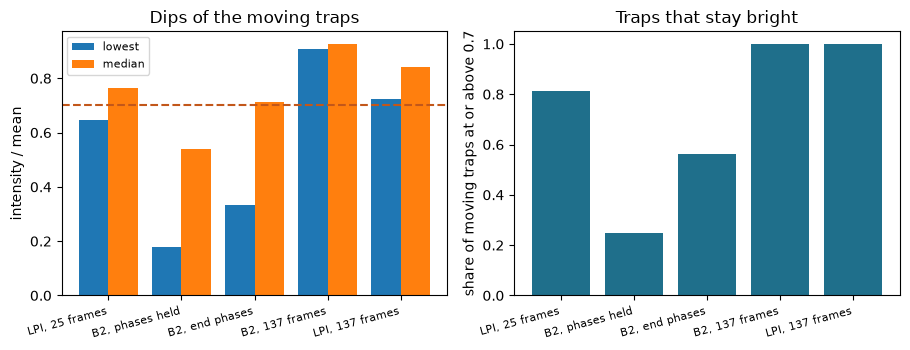

In [9]:
# the five sequences of the long sort: lowest and median intensity of the moving traps, and the share at or
# above 0.7
fig, (a, b) = plt.subplots(1, 2, figsize=(9.2, 3.6))
slots = np.arange(len(stress))
a.bar(slots - 0.2, [r.min() for r in stress.values()], 0.4, label="lowest")
a.bar(slots + 0.2, [np.median(r) for r in stress.values()], 0.4, label="median")
a.axhline(0.7, color="#c2571a", linestyle="--")
b.bar(slots, [np.mean(r >= 0.7) for r in stress.values()], color="#1f6f8b")
for ax in (a, b):
    ax.set_xticks(slots)
    ax.set_xticklabels(list(stress), rotation=15, ha="right", fontsize=8)
a.set_ylabel("intensity / mean")
b.set_ylabel("share of moving traps at or above 0.7")
a.legend(fontsize=8)
a.set_title("Dips of the moving traps")
b.set_title("Traps that stay bright")
plt.tight_layout()
plt.show()

At 25 frames the claim does not carry over, and LPI is the better sequence. B2 with the phases held collapses, with a lowest moving trap at 0.177, a median of 0.540 and a quarter of the moving traps at or above 0.7: the phases of the start are not the ones that make the traps equal at the end of the move. Giving B2 the end phases repairs part of this, with a lowest of 0.333, a median of 0.714 and 56.2 percent at or above 0.7, but LPI is ahead on all three measures, with a lowest of 0.646, a median of 0.764 and 81.2 percent at or above 0.7: at 25 frames the end-phase path of B2 moves the phases too fast for the frames to follow. With the frames the move needs, 137, the order turns: B2 keeps every moving trap at or above 0.909 of its mean, with a median of 0.927, which meets the 0.9 of the claim, while LPI with as many frames has a lowest of 0.725 and a median of 0.843, with every trap at or above 0.7 but none of its worst near 0.9. The comparison is of one loading and one seed, with two frame counts, and it rests on the pipeline's transient model.

## Results

**Answer:** Yes for the short moves of the acceptance task, and for the long moves of a full sort only with the frames the move needs. On the acceptance task, 8 of 16 traps moving 4 bins, B2 has a lowest transient intensity of 0.916, 0.920 and 0.926 of the mean over three seeds, above the 0.9 asked, against 0.669, 0.700 and 0.642 for LPI under the same transient model, with every single frame of B2 uniform to 0.39 percent or better. On the sort of case C10, 16 traps moving up to 29.0 bins on M16's own plan, 25 frames are not enough: B2 with the phases held falls to a lowest of 0.177, with the end phases it reaches a lowest of 0.333 and a median of 0.714, and LPI leads on every measure, with a lowest of 0.646, a median of 0.764 and 81.2 percent of the moving traps at or above 0.7. With the 137 frames that `frames_for_move` names, B2 with the end phases keeps every moving trap at or above 0.909 of its mean (one seed here; 0.899 to 0.919 over six seeds in the record), and LPI with as many frames reaches 0.725.

What the notebook does not show is a hardware measurement of the dips, more than one loading, or the dependence on the number of frames beyond the values used.

## Summary

- B2 locks the trap phases to a smooth trajectory and re-optimises each frame with phase-fixed WGS; LPI interpolates two independent holograms and optimises nothing between them.
- Both are scored here by one transient model, which blends consecutive frames and is unverified in absolute terms.
- On the acceptance task B2 keeps the lowest moving trap at 0.916 to 0.926 of its mean against 0.642 to 0.700 for LPI.
- On the long moves of C10 the phases of the start cannot be held, and at 25 frames LPI beats the end-phase B2 on every measure; with the 137 frames the move needs, B2 meets 0.9 (0.909) and LPI does not (0.725).
- On this seed the claim holds when the frames follow the move. The product's record finds 5 of 6 seeds at or above 0.9 on C10 (0.899 to 0.919) and 6 of 8 on long lattice moves, where the limit is the phase path that the end phases prescribe, so the frame count is a condition, not the whole limit.

## References

- Parallel assembly of neutral atom arrays with an SLM using linear phase interpolation. https://arxiv.org/abs/2501.01391
- Lee, Kim and Ahn (2017). Defect-free atomic array formation using the Hungarian matching algorithm. Physical Review A 95, 053424. https://doi.org/10.1103/PhysRevA.95.053424
- Kim et al. (2019). Large-scale uniform optical focus array generation with a phase spatial light modulator. Optics Letters 44, 3178. https://doi.org/10.1364/OL.44.003178